# Support vector machines and kernels: geometry, constraints, and certificates

## 1. Introduction and learning objectives

Support vector machines connect a geometric margin to a convex constrained objective. Kernels replace explicit feature coordinates with inner products, changing representation without removing computational cost. This chapter makes the optimization conditions observable: a fitted classifier includes feasibility checks, a primal/dual gap, and a convergence flag. A plausible separating plot is insufficient evidence that a constrained problem was solved.

Explain functional and geometric margins; derive a soft-margin primal and dual; implement hinge subgradients and linear/polynomial/RBF kernels; solve small dual problems with projected gradient ascent; and verify exact examples, feasibility and optimality gaps. Evaluate representation, regularization and computational limits with matched local data. The solver is a bounded teaching implementation, not a production SVM optimizer.

**Prerequisites:** Stage 00 matrix calculus, finite differences, positive-semidefinite matrices and stable arithmetic; Stage 01 regularization and evaluation; [information and decisions](probability-information-and-decisions.ipynb). Signed binary labels use $y_i\in\{-1,+1\}$ and shape $(n,)$. Features have shape $(n,d)$. No external optimization package or autodifferentiation is used.

## 2. Prerequisites and mathematical foundations

Let $f(x)=w^Tx+b$. Functional margin is $y_i f(x_i)$; for $w\ne0$ geometric signed margin is $y_i f(x_i)/\|w\|$. Rescaling $(w,b)$ by a positive constant changes the functional margin but preserves the boundary and geometric margin. Canonical hard-margin constraints $y_i f(x_i)\ge1$ remove this scaling freedom; their two parallel margin planes are separated by $2/\|w\|$. A zero vector has no defined normalized geometric margin.

For potentially overlapping classes, our soft-margin objective is
$$P(w,b)=\frac12\|w\|^2+C\sum_{i=1}^n\max(0,1-y_i(w^Tx_i+b)),\qquad C>0.$$
The bias is unpenalized. This uses a **sum** of hinge losses. The equivalent mean-loss convention $n^{-1}\sum_i\mathrm{hinge}_i+\lambda\|w\|^2/2$ has $C=1/(n\lambda)$ when $\lambda>0$. Duplicating rows with unchanged $C$ changes the balance; halve $C$ when duplicating every row twice to preserve the corresponding objective.

Hinge loss has derivative $-y_i x_i$ with respect to $w$ when the margin is below one and zero above one. At margin exactly one it has a set of subgradients, $-\theta y_i x_i$ for $\theta\in[0,1]$, with a matching bias component $-\theta y_i$. The reference chooses $\theta=0$ there. A central difference at the kink generally returns the midpoint, not necessarily the selected valid subgradient.

**Study workflow:** attempt each dedicated answer first, then reveal its hint or worked solution. Reference Python is displayed Markdown and is not executed by Run All. Snippet dependencies refer only to this chapter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Exercise 02.06.01 — Separate a margin from a probability

**Type:** Conceptual · **Answer:** Markdown

For $w=(3,4)$, $b=-1$, and signed point $x=(1,1),y=1$, compute functional/geometric margins. Multiply $(w,b)$ by two and compare the boundary and both margins. Can either score be interpreted as a calibrated class probability?

**Expected outcome:** margins $6$ and $6/5$, the scaling distinction, and an explicit probability limitation.

**Your response to Exercise 02.06.01**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.06.01**

The norm is five before scaling. Classification scores can be any real value.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.06.01**

The score is $3+4-1=6$, so the functional margin is $6$ and geometric margin is $1.2$. Doubling weights and bias gives score $12$ and norm $10$, preserving the geometric margin and boundary. Neither a signed distance nor a raw margin is a probability. Any later probability calibration requires its own estimator, validation data and probability-quality evaluation. A successful separation alone does not establish calibration or robustness to a changed input distribution.

</details>

## 3. Theoretical development and worked examples

### Derive a dual rather than treating it as a new loss

Introduce slack $\xi_i\ge0$ and constraints $y_i(w^Tx_i+b)\ge1-\xi_i$. Lagrange multipliers $\alpha_i\ge0$ apply to the margin constraints and $\mu_i\ge0$ to $-\xi_i\le0$. Stationarity gives
$$w=\sum_i\alpha_i y_i x_i,\qquad \sum_i\alpha_i y_i=0,\qquad C-\alpha_i-\mu_i=0.$$
Thus $0\le\alpha_i\le C$. Substitution produces the dual maximization
$$D(\alpha)=\mathbf1^T\alpha-\frac12\alpha^TQ\alpha,\qquad Q_{ij}=y_i y_j K(x_i,x_j),\quad y^T\alpha=0.$$
For a linear kernel $K(x,z)=x^Tz$, this is the same classifier as the primal above. For a positive-semidefinite kernel it defines the analogous regularized problem in its feature space, with squared norm $\alpha^TQ\alpha$. The unpenalized bias is the reason for the equality constraint. Box clipping alone is not the required projection.

With scores $g_i=\sum_j\alpha_j y_jK(x_i,x_j)$ before adding bias, optimal KKT conditions imply: $\alpha_i=0$ permits margin $y_i(g_i+b)\ge1$; $0\lt\alpha_i\lt C$ requires margin one; $\alpha_i=C$ permits margin at most one. A bound support vector can be inside the margin or misclassified. The rule that every support vector lies exactly on the margin is too strong for soft-margin problems.

At a free support vector $b=y_i-g_i$; average these values numerically. If none is free, the bound inequalities define lower/upper admissible bias limits. Their midpoint is usable when consistent; an inverted interval from an unfinished solve is a diagnostic, not a certificate. For any primal scores and feasible dual vector, $D\le P$; the nonnegative gap $P-D$ bounds suboptimality of both objectives under this convex formulation. A small gap is an optimization statement, not a test-accuracy guarantee.

**Exact two-point problem:** $x=(-1,1)$, $y=(-1,1)$, $b=0$. Equality forces $\alpha_1=\alpha_2=a$. Then $D=2a-2a^2$, so $a^*=\min(C,1/2)$ and $w=2a^*$. For $C=1$, $a=.5$, $w=1$ and $P=D=.5$. For $C=.1$, $a=.1$, $w=.2$ and $P=D=.18$; both points are bound support vectors with margin $.2$, not one.

### Kernels and representation

A kernel satisfies $K(x,z)=\langle\phi(x),\phi(z)\rangle$ for a feature map. Every finite Gram matrix is then symmetric PSD because $v^TKv=\|\sum_i v_i\phi(x_i)\|^2\ge0$. Symmetry and positive entries alone are insufficient. A PSD check on one observed matrix also does not prove a function is a valid kernel for all possible input sets.

We implement linear $x^Tz$, polynomial $(\gamma x^Tz+c)^p$ with $\gamma>0,c\ge0$ and positive integer degree, and RBF $e^{-\gamma\|x-z\|^2}$. For two-dimensional inputs, $(1+x^Tz)^2$ has the explicit map
$$\phi(x)=(1,\sqrt2x_0,\sqrt2x_1,x_0^2,\sqrt2x_0x_1,x_1^2).$$
Expand its dot product independently. These feature maps connect linear models and nonlinear representations. A learned neural representation later changes the map using data; the fixed-kernel examples do not learn it. RBF bandwidth depends on feature units, so preprocessing and its fit boundary are part of the model.

For RBF validity, write $K(x,z)=e^{-\gamma\|x\|^2}e^{-\gamma\|z\|^2}\sum_{m=0}^{\infty}(2\gamma)^m(x^Tz)^m/m!$. Each integer dot-product power is an inner product of tensor features, all series coefficients are nonnegative, and multiplying by one factor per input preserves PSD. On every fixed finite input set the series converges, and the PSD quadratic-form inequality survives the limit. This supplies a construction argument beyond testing a few eigenvalues.

### A small projected dual optimizer

The negative dual has gradient $Q\alpha-\mathbf1$ and Lipschitz constant $L=\lambda_{\max}(Q)=\lambda_{\max}(K)$, since multiplying rows/columns by signed labels is an orthogonal similarity. Use ascent step $1/\max(1,L)$ and project onto the intersection of the box and $y^T\alpha=0$.

For Euclidean projection of $v$, stationarity gives $\alpha_i(\nu)=\operatorname{clip}(v_i-\nu y_i,0,C)$. The scalar function $y^T\alpha(\nu)$ is continuous and nonincreasing; bracket a zero and bisect. This solves a constrained **projection**, not an SVM by itself. The outer loop checks feasibility and gap with fixed work limits; it returns an unfinished status if the gap target was not reached.

Training is intentionally limited to at most 128 rows. Full Gram storage is $8n^2$ bytes in float64, eigenvalue validation costs $O(n^3)$, and each outer matrix-vector step costs $O(n^2)$ plus a bounded projection. RBF distances accumulate one coordinate at a time without an $(n,m,d)$ tensor. Query prediction uses blocks. These limits make explicit why a kernel trick can save feature dimensions while still being unsuitable for large sample counts.

### Exercise 02.06.02 — Recover the primal, dual and normalization

**Type:** Mathematical · **Answer:** Markdown

Derive the stationarity equations, box and equality constraints, and dual quadratic. Explain weak duality and which convex assumptions justify the optimum comparison here. Convert between $C$ and the mean-loss regularization parameter. What changes if the bias is also penalized?

**Expected outcome:** the full constrained dual with signs and factors correct, a normalization map and a bias-constraint explanation.

**Your response to Exercise 02.06.02**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.06.02**

Differentiate the Lagrangian separately with respect to $w$, $b$ and each slack before substituting anything.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.06.02**

The Lagrangian is $\|w\|^2/2+C\sum_i\xi_i+\sum_i\alpha_i[1-\xi_i-y_i(w^Tx_i+b)]-\sum_i\mu_i\xi_i$. Stationarity yields the three equations above. Nonnegative $\mu_i=C-\alpha_i$ gives the upper box bound, while the unpenalized bias imposes $y^T\alpha=0$. Substitution gives the negative quadratic with factor $1/2$. Feasible dual values lower-bound feasible primal values. A PSD kernel gives a convex primal, and strictly feasible slack choices supply the usual strong-duality condition for this finite problem. Multiplying the mean-loss objective by $1/\lambda$ gives $C=1/(n\lambda)$. Penalizing the bias changes its stationarity relation, so retaining this equality-constrained dual would solve the wrong problem.

</details>

### Exercise 02.06.03 — Solve the two-point problem independently

**Type:** Numerical · **Answer:** Markdown

Compute both optimal dual coefficients, weight, margins, hinge sum, primal and dual values for $C=1$ and $C=.1$. Identify free versus bound support vectors and explain why the smaller-$C$ example has positive hinge loss at its optimum.

**Expected outcome:** $(a,w,P,D)=(.5,1,.5,.5)$ and $(.1,.2,.18,.18)$ with explicit slack costs.

**Your response to Exercise 02.06.03**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.06.03**

Differentiate $2a-2a^2$ subject to $0\le a\le C$. Use the original summed primal to check the result.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.06.03**

The unconstrained maximum is $a=.5$. At $C=1$ both coefficients are free, margins are one and hinge sum is zero, giving primal $1/2$. At $C=.1$ coefficients are at the upper bound; margins are $.2$, hinge sum is $1.6$ and primal is $.2^2/2+.1(1.6)=.18$. The dual is $.2-2(.1)^2=.18$. Allowing margin violations trades their cost against norm reduction. A finite low-$C$ optimum is not required to separate at the canonical unit margin.

</details>

### Exercise 02.06.04 — Verify a feature map and reject an invalid Gram matrix

**Type:** Mathematical · **Answer:** Markdown

Expand the given degree-two feature map and show its inner product equals $(1+x^Tz)^2$. For $K=\begin{pmatrix}1&2\\2&1\end{pmatrix}$, exhibit a vector with negative quadratic form. Explain why testing several PSD Gram matrices would still not prove universal kernel validity.

**Expected outcome:** cross-term factors, quadratic form $-2$ for $(1,-1)$, and a finite-check versus universal-proof distinction.

**Your response to Exercise 02.06.04**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.06.04**

The $\sqrt2$ factors create the doubled first-order and cross terms. Kernel validity quantifies over every finite input set.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.06.04**

The feature dot product is $1+2x_0z_0+2x_1z_1+x_0^2z_0^2+2x_0x_1z_0z_1+x_1^2z_1^2$, which is the required square. With $v=(1,-1)$ the proposed Gram quadratic is $1+1-4=-2$, ruling it out as an inner-product matrix. Symmetry and entrywise positivity did not suffice. Passing finitely many sampled PSD checks only rules out those sampled counterexamples; a construction, closure theorem or other universal argument is needed for a kernel function over its entire domain.

</details>

## 4. Guided exercises

### Exercise 02.06.05 — Implement the summed hinge primal and subgradient

**Type:** Programming · **Answer:** Code

Implement `hinge_primal(X, labels, weights, bias, C)`. Return objective and weight/bias subgradients, using zero hinge contribution at exact margin one. Independently finite-difference away from all kinks. Check observation duplication with adjusted versus unchanged $C$.

**Expected outcome:** correct norm/hinge factors, unpenalized bias and a derivative check restricted to differentiable snapshots.

In [ ]:
# Your code for Exercise 02.06.05.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.06.05**

The active set is `margin < 1`. The observation sum has no extra average.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.06.05**

This is a loss/subgradient evaluator, not the final dual optimizer. At a kink, the chosen zero hinge subgradient is valid even if central differences return a different member of the subgradient interval.

~~~python
def hinge_primal(X, labels, weights, bias, C):
    X = np.asarray(X,dtype=float); y = np.asarray(labels,dtype=float)
    w = np.asarray(weights,dtype=float)
    if X.ndim != 2 or min(X.shape) == 0 or y.shape != (len(X),) or w.shape != (X.shape[1],):
        raise ValueError('nonempty compatible feature, label and weight arrays required')
    if not all(np.isfinite(a).all() for a in (X,y,w)) or not np.isfinite(bias) or not np.isfinite(C) or C <= 0 or not np.isin(y,[-1.,1.]).all():
        raise ValueError('finite inputs, signed labels and positive C required')
    with np.errstate(over='raise',invalid='raise'):
        margin = y*(X@w+bias); active = margin < 1
        objective = .5*(w@w)+C*np.maximum(0,1-margin).sum()
        dw = w-C*(X[active].T@y[active]); db = -C*y[active].sum()
    return float(objective),dw,float(db)

assert np.isclose(hinge_primal([[-1.],[1.]],[-1,1],[.2],0.,.1)[0],.18)
~~~

</details>

### Exercise 02.06.06 — Compute bounded linear, polynomial and RBF kernels

**Type:** Programming · **Answer:** Code

Implement `kernel_matrix(X, Z, kind='linear', gamma=1., degree=2, offset=1.)`. Require finite compatible matrices, positive gamma, nonnegative offset and integer degree 1–4. Do not form a three-dimensional distance tensor. Check symmetry, explicit degree-two features and known RBF values. A numerical PSD check is an additional test, not your validity proof.

**Expected outcome:** correct cross-Gram shapes, empty-query support, direct-distance stability and explicit range failures.

In [ ]:
# Your code for Exercise 02.06.06.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.06.06**

For RBF, accumulate squared coordinate differences into a two-dimensional matrix. Linear kernels need not have positive entries.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.06.06**

The polynomial parameter restrictions ensure the stated standard kernel construction. Squared distance is computed directly to avoid cancellation from a norm-expansion identity. Overflow is reported; exponent underflow to zero for very distant points is permitted.

~~~python
def kernel_matrix(X, Z, kind='linear', gamma=1., degree=2, offset=1.):
    X = np.asarray(X,dtype=float); Z = np.asarray(Z,dtype=float)
    if X.ndim != 2 or Z.ndim != 2 or X.shape[1] == 0 or X.shape[1] != Z.shape[1] or not np.isfinite(X).all() or not np.isfinite(Z).all():
        raise ValueError('finite compatible feature matrices required')
    if not np.isfinite(gamma) or gamma <= 0 or not np.isfinite(offset) or offset < 0:
        raise ValueError('positive gamma and nonnegative offset required')
    if isinstance(degree,(bool,np.bool_)) or not isinstance(degree,(int,np.integer)) or not 1 <= degree <= 4:
        raise ValueError('integer polynomial degree 1..4 required')
    with np.errstate(over='raise',invalid='raise'):
        if kind == 'linear':
            result = X@Z.T
        elif kind == 'polynomial':
            result = (gamma*(X@Z.T)+offset)**degree
        elif kind == 'rbf':
            squared = np.zeros((len(X),len(Z)))
            for j in range(X.shape[1]):
                difference = X[:,j,None]-Z[None,:,j]
                squared += difference*difference
            result = np.exp(-gamma*squared)
        else:
            raise ValueError('unknown kernel')
    if not np.isfinite(result).all():
        raise FloatingPointError('kernel outside finite range')
    return result

assert np.allclose(kernel_matrix([[0.]],[[1.]],'rbf'), np.exp(-1))
~~~

</details>

## 5. Implementation challenges

The following projection and optimizer use fixed iteration budgets and explicit tolerances. Keep the learning objective and the solver's stopping criterion separate. Do not silently treat a budget-limited run as a converged reference. The required Gram sizes are tiny; later systems chapters revisit algorithmic and hardware efficiency.

### Exercise 02.06.07 — Project onto both dual constraints

**Type:** Programming · **Answer:** Code

Implement `project_svm_dual(values, labels, C)` using the scalar clipped form and at most 80 bisections. Require both signed classes. Return a box-feasible vector satisfying the equality to a declared numerical tolerance, or report a range/accuracy failure. Give an example where clipping alone violates the equality.

**Expected outcome:** box/equality checks, an independently solved two-coordinate projection and no hidden equality penalty replacing the constraint.

In [ ]:
# Your code for Exercise 02.06.07.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.06.07**

A sufficiently low multiplier makes positive-label coefficients saturate and negative-label coefficients zero; a high multiplier reverses those roles.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.06.07**

This projects Euclidean distance, so the Lagrange multiplier is subtracted as `nu*y`. The bracket is constructed from all positive/negative coordinates. Finite bisection and a final residual check make the numerical contract visible.

~~~python
def project_svm_dual(values, labels, C):
    v = np.asarray(values,dtype=float); y = np.asarray(labels,dtype=float)
    if v.ndim != 1 or len(v) < 2 or y.shape != v.shape or not np.isfinite(v).all() or not np.isin(y,[-1.,1.]).all() or len(np.unique(y)) != 2 or not np.isfinite(C) or C <= 0:
        raise ValueError('finite vector, both signed labels and positive C required')
    with np.errstate(over='raise',invalid='raise'):
        lower = min(float(np.min(v[y == 1]-C)),float(np.min(-v[y == -1])))
        upper = max(float(np.max(v[y == 1])),float(np.max(C-v[y == -1])))
        for _ in range(80):
            nu = lower/2+upper/2
            projected = np.clip(v-nu*y,0,C)
            imbalance = float(y@projected)
            if abs(imbalance) <= 1e-12:
                break
            if imbalance > 0:
                lower = nu
            else:
                upper = nu
    if abs(y@projected) > 1e-9*max(1.,len(v)*C):
        raise FloatingPointError('projection equality tolerance was not reached')
    return projected

assert np.allclose(project_svm_dual([.8,.2],[-1,1],1.),[.5,.5])
~~~

</details>

### Exercise 02.06.08 — Recover bias and report optimization diagnostics

**Type:** Programming · **Answer:** Code

Implement `svm_diagnostics(gram, labels, alpha, C)` for compatible finite arrays from a feasible dual solve. Return bias, margins, primal, dual, gap and maximum KKT margin violation. Use free-support-vector equalities when present and bound inequalities otherwise. Document the numerical bound threshold; report inverted bias intervals instead of asserting they certify convergence.

**Expected outcome:** both two-point examples, free/bound KKT distinctions and independent primal/dual calculations.

In [ ]:
# Your code for Exercise 02.06.08.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.06.08**

For positive labels, zero coefficients give a lower bias bound and upper-bound coefficients give an upper bound. Reverse those directions for negative labels.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.06.08**

The helper below consumes solver-validated inputs. Its cutoff `min(1e-7, C*1e-6)` classifies approximate bounds for diagnostics. A midpoint of inconsistent limits is only a candidate bias for an unfinished iterate; `bias_interval_valid` records that fact. The gap is reported without flooring a negative numerical value.

~~~python
def svm_diagnostics(gram, labels, alpha, C):
    y = np.asarray(labels,dtype=float); alpha = np.asarray(alpha,dtype=float)
    coefficients = alpha*y; raw = gram@coefficients
    bound = min(1e-7,C*1e-6)
    zero = alpha <= bound; capped = alpha >= C-bound
    free = ~(zero|capped)
    interval_valid = True
    if free.any():
        bias = float(np.mean(y[free]-raw[free]))
    else:
        lower_values = np.r_[1-raw[(y == 1)&zero],-1-raw[(y == -1)&capped]]
        upper_values = np.r_[1-raw[(y == 1)&capped],-1-raw[(y == -1)&zero]]
        lower = float(lower_values.max()) if len(lower_values) else -np.inf
        upper = float(upper_values.min()) if len(upper_values) else np.inf
        interval_valid = lower <= upper+1e-10
        bias = lower/2+upper/2 if np.isfinite(lower) and np.isfinite(upper) else (lower if np.isfinite(lower) else upper)
    margin = y*(raw+bias); norm_squared = float(coefficients@raw)
    primal = .5*norm_squared+C*np.maximum(0,1-margin).sum()
    dual = alpha.sum()-.5*norm_squared
    violation = np.where(zero,np.maximum(0,1-margin),np.where(capped,np.maximum(0,margin-1),np.abs(margin-1)))
    return dict(bias=float(bias),margins=margin,primal=float(primal),dual=float(dual),
                gap=float(primal-dual),kkt_violation=float(violation.max()),bias_interval_valid=bool(interval_valid))

demo_small_K = kernel_matrix([[-1.],[1.]],[[-1.],[1.]])
assert np.isclose(svm_diagnostics(demo_small_K,[-1,1],[.1,.1],.1)['gap'],0)
~~~

</details>

### Exercise 02.06.09 — Optimize the small PSD-kernel dual

**Type:** Programming · **Answer:** Code

Implement `fit_svm_dual` with validated symmetric PSD Gram matrix, feasible projected steps, at most a fixed positive iteration budget, and a relative primal/dual gap target. Record diagnostic checkpoints and a convergence flag. Check that one deliberately short run remains explicitly unfinished. A small tested Gram matrix does not establish universal kernel validity.

**Expected outcome:** exact two-point optima, feasible iterates, nondecreasing dual up to numerical tolerance, and honest budget exhaustion.

In [ ]:
# Your code for Exercise 02.06.09.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.06.09**

Start at zero coefficients. The dual ascent gradient is `1 - Q @ alpha`. Use a safe spectral step and check the primal certificate after recovering a bias.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.06.09**

This depends on `project_svm_dual` and `svm_diagnostics`. Tiny negative eigenvalues within a stated roundoff tolerance are accepted; material indefiniteness is rejected. The gap criterion is `gap <= tolerance * max(1, abs(primal))` with a separate lower-bound sanity check. This projected method is different from SMO and keeps dense-work limits explicit.

~~~python
def fit_svm_dual(gram, labels, C=1., tolerance=1e-5, max_steps=2000):
    K = np.asarray(gram,dtype=float); y = np.asarray(labels,dtype=float)
    if K.ndim != 2 or K.shape[0] != K.shape[1] or not 2 <= len(K) <= 128 or y.shape != (len(K),) or not np.isfinite(K).all() or not np.isin(y,[-1.,1.]).all() or len(np.unique(y)) != 2:
        raise ValueError('finite square Gram (2..128 rows) and both signed classes required')
    if not np.isfinite(C) or C <= 0 or not np.isfinite(tolerance) or tolerance <= 0:
        raise ValueError('positive finite C and tolerance required')
    if isinstance(max_steps,(bool,np.bool_)) or not isinstance(max_steps,(int,np.integer)) or not 1 <= max_steps <= 10000:
        raise ValueError('integer iteration budget 1..10000 required')
    if not np.allclose(K,K.T,rtol=1e-12,atol=1e-12):
        raise ValueError('symmetric Gram required')
    K = K/2+K.T/2; eigenvalues = np.linalg.eigvalsh(K)
    if eigenvalues[0] < -1e-10*max(1.,abs(eigenvalues[-1])):
        raise ValueError('Gram is materially indefinite')
    Q = y[:,None]*K*y[None,:]; step = 1/max(1.,float(eigenvalues[-1]))
    alpha = np.zeros(len(y)); history = []; converged = False
    for iteration in range(max_steps+1):
        if iteration % 10 == 0 or iteration == max_steps:
            diagnostic = svm_diagnostics(K,y,alpha,C)
            gap, primal = diagnostic['gap'],diagnostic['primal']
            if not np.isfinite(gap) or gap < -1e-7*max(1.,abs(primal)):
                raise FloatingPointError('invalid primal/dual gap')
            history.append((iteration,primal,diagnostic['dual'],gap))
            converged = gap <= tolerance*max(1.,abs(primal))
            if converged or iteration == max_steps:
                break
        with np.errstate(over='raise',invalid='raise'):
            alpha = project_svm_dual(alpha+step*(1-Q@alpha),y,C)
    return dict(alpha=alpha,coefficients=alpha*y,iterations=iteration,converged=bool(converged),
                history=np.array(history),C=float(C),**diagnostic)

demo_dual = fit_svm_dual(demo_small_K,[-1,1],C=1.)
assert demo_dual['converged'] and np.allclose(demo_dual['alpha'],.5)
~~~

</details>

### Exercise 02.06.10 — Fit and predict with query blocks

**Type:** Programming · **Answer:** Code

Implement `fit_kernel_svm` and `predict_kernel_svm`. Preserve a private copy of training features and signed coefficients; retain solver diagnostics. Predict with blocks of at most `query_block` rows and return signed labels (zero-score tie chooses $+1$) and raw scores. Keep scaling outside the model, learned from the permitted training split only.

**Expected outcome:** direct linear-score equivalence, nonlinear cross-Gram checks, empty-query support and matching predictions across query block sizes.

In [ ]:
# Your code for Exercise 02.06.10.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.06.10**

Use $K(X_\mathrm{query},X_\mathrm{train})(\alpha\odot y)+b$. A raw score is not a probability.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.06.10**

These wrappers depend on the earlier kernel and dual references. No support-vector threshold silently changes the predictor: all coefficients are retained. This costs a little extra work at these tiny sizes and keeps the numerical definition identical to the solved model.

~~~python
def fit_kernel_svm(X, labels, C=1., kind='linear', gamma=1., degree=2, offset=1., tolerance=1e-5, max_steps=2000):
    X = np.asarray(X,dtype=float)
    parameters = dict(kind=kind,gamma=gamma,degree=degree,offset=offset)
    result = fit_svm_dual(kernel_matrix(X,X,**parameters),labels,C,tolerance,max_steps)
    result.update(train_X=X.copy(),kernel_parameters=parameters)
    return result

def predict_kernel_svm(model, X, query_block=64):
    X = np.asarray(X,dtype=float)
    if X.ndim != 2 or X.shape[1] != model['train_X'].shape[1] or not np.isfinite(X).all():
        raise ValueError('finite query matrix with matching width required')
    if isinstance(query_block,(bool,np.bool_)) or not isinstance(query_block,(int,np.integer)) or query_block < 1:
        raise ValueError('positive integer query block required')
    scores = np.empty(len(X))
    for start in range(0,len(X),query_block):
        stop = min(start+query_block,len(X))
        scores[start:stop] = kernel_matrix(X[start:stop],model['train_X'],**model['kernel_parameters'])@model['coefficients']+model['bias']
    return np.where(scores >= 0,1,-1),scores

demo_model = fit_kernel_svm([[-1.],[1.]],[-1,1])
assert np.array_equal(predict_kernel_svm(demo_model,[[-2.],[2.]])[0],[-1,1])
~~~

</details>

## 6. Experiments and visualizations

The first demonstration shows the **given two-point analytic solution**, not a fitted challenge. The second plots hinge loss alongside zero-one loss under the convention that a zero margin is counted as an error for that illustrative loss curve. The classifier's explicit zero-score tie rule is a separate prediction convention. Hinge loss upper-bounds this zero-one curve but is not a probability model.

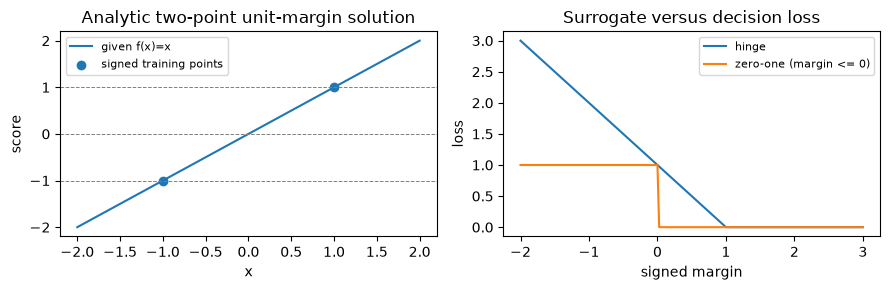

In [2]:
fig, axes = plt.subplots(1,2,figsize=(9,3))
demo_coordinate = np.linspace(-2,2,201)
axes[0].plot(demo_coordinate,demo_coordinate,label='given f(x)=x')
axes[0].scatter([-1,1],[-1,1],label='signed training points')
for level in (-1,0,1):
    axes[0].axhline(level,color='gray',linestyle='--',linewidth=.7)
axes[0].set(xlabel='x',ylabel='score',title='Analytic two-point unit-margin solution')
axes[0].legend(fontsize=8)
demo_margin = np.linspace(-2,3,201)
demo_hinge = np.maximum(0,1-demo_margin); demo_zero_one = (demo_margin <= 0).astype(float)
axes[1].plot(demo_margin,demo_hinge,label='hinge')
axes[1].plot(demo_margin,demo_zero_one,label='zero-one (margin <= 0)')
axes[1].set(xlabel='signed margin',ylabel='loss',title='Surrogate versus decision loss')
axes[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

### Exercise 02.06.11 — Compare representation under a fixed solver budget

**Type:** Experimental · **Answer:** Code

For seeds 230–232, independently generate 48 training and 80 validation rows, balanced by class. Negative-class radius is $.7$ and positive-class radius $1.5$, each with independent normal noise of standard deviation $.1$; angles are uniform on $[0,2\pi)$. Compare linear kernels with $C\in\{.1,1\}$ and RBF kernels with $C=1$, $\gamma\in\{.5,2\}$. Use at most 2000 outer iterations and tolerance $10^{-5}$. Report validation error, objective gap, KKT residual, convergence status, elapsed time and Gram bytes for every candidate. Do not drop unfinished runs or silently enlarge their budgets.

**Expected outcome:** measured paired comparisons and a distinction between representation error and incomplete optimization.

In [ ]:
# Your code for Exercise 02.06.11.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.06.11**

Create each split once per seed and use identical rows for all candidates. A linear classifier cannot represent a concentric-ring boundary in raw coordinates.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.06.11**

This depends on fit/predict/kernel references. The stated generative geometry motivates a nonlinear representation, but finite validation results and convergence still need measurement. A fixed iteration budget can yield different gaps across kernels, which is a material comparison limitation. No test rows are used for tuning in this study.

~~~python
from time import perf_counter

demo_svm_records = []
for seed in range(230,233):
    rng = np.random.default_rng(seed); data = []
    for per_class in (24,40):
        y = np.repeat([-1,1],per_class)
        radius = np.repeat([.7,1.5],per_class)+rng.normal(0,.1,2*per_class)
        angle = rng.uniform(0,2*np.pi,2*per_class)
        X = radius[:,None]*np.column_stack([np.cos(angle),np.sin(angle)])
        data.append((X,y))
    (train_X,train_y),(valid_X,valid_y) = data
    for kind,C,gamma in (('linear',.1,1.),('linear',1.,1.),('rbf',1.,.5),('rbf',1.,2.)):
        started = perf_counter()
        model = fit_kernel_svm(train_X,train_y,C,kind,gamma,tolerance=1e-5,max_steps=2000)
        predictions,_ = predict_kernel_svm(model,valid_X,query_block=32)
        demo_svm_records.append((seed,kind,C,gamma,float(np.mean(predictions != valid_y)),
                                 model['gap'],model['kkt_violation'],model['converged'],
                                 perf_counter()-started,8*len(train_X)**2))
assert len(demo_svm_records) == 12
print('Measured SVM validation and optimization records:',demo_svm_records)
~~~

</details>

### Exercise 02.06.12 — Control normalization when sample count changes

**Type:** Experimental · **Answer:** Code

Use the two-point example at $C=.1$. Duplicate each observation twice and fit once with unchanged $C$ and once with $C/2$. Compare raw prediction slopes, summed hinge loss, objective and solver gaps. Explain why a model-selection grid over $C$ cannot be interpreted independently of the loss normalization and sample count.

**Expected outcome:** preserved slope $.2$ after adjusting $C$, slope $.4$ when leaving $C$ unchanged, and explicitly comparable objective definitions.

In [ ]:
# Your code for Exercise 02.06.12.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.06.12**

Duplicating rows doubles the hinge sum without changing the norm term. Multiple dual coefficient representations can correspond to the same primal weight.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.06.12**

This depends on the linear kernel references. The duplicated model need not assign the same individual coefficients because its training representation has changed. Compare the combined primal weight and predictions rather than requiring coefficient-by-coefficient identity across different-length datasets.

~~~python
demo_original = fit_kernel_svm([[-1.],[1.]],[-1,1],C=.1)
demo_duplicated_X = np.array([[-1.],[-1.],[1.],[1.]])
demo_duplicated_y = np.array([-1,-1,1,1])
demo_adjusted = fit_kernel_svm(demo_duplicated_X,demo_duplicated_y,C=.05)
demo_unchanged = fit_kernel_svm(demo_duplicated_X,demo_duplicated_y,C=.1)
demo_slopes = [float(model['train_X'][:,0]@model['coefficients'])
               for model in (demo_original,demo_adjusted,demo_unchanged)]
assert np.allclose(demo_slopes,[.2,.2,.4])
~~~

</details>

## 7. Interpretation and critical analysis

A valid kernel and convex objective make certain optimization claims possible. They do not validate the features, class costs, sampling design or evaluation metric. Feature scale changes the margin norm and RBF geometry; high accuracy does not certify probability quality. Dense kernels also exchange an explicit feature dimension for a sample-count cost. Always report the solver certificate and the prediction metric separately.

### Bounded primary-source study

Read [CS229 Kernel Methods, §1.4](https://cs229.stanford.edu/summer2020/cs229-notes3.pdf) for explicit feature constructions and kernel validity. Translate one feature map into a small array calculation, independently verify an identity, and distinguish a construction valid for every input from a sampled Gram check. This scope does not reproduce the source's later SMO optimizer; our projected solver is explicitly a different algorithm.

### Exercise 02.06.13 — Audit the scope of a kernel-validity argument

**Type:** Critical · **Answer:** Markdown

Document a source feature-map equation, your chosen input dimensions and parameters, an independent inner-product check, and a counterexample to the statement that every positive symmetric similarity is a valid kernel. Explain why a small solver gap cannot establish universal kernel validity or predictive usefulness.

**Expected outcome:** one bounded primary-source connection, an exact algebraic claim and separate numerical/experimental limitations.

**Your response to Exercise 02.06.13**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.06.13**

An observed PSD matrix is about one finite set. A kernel definition quantifies over all finite sets in its input domain.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.06.13**

Use the degree-two map to prove the identity symbolically and compare a small explicit feature matrix with the implicit Gram. The positive symmetric $2\times2$ counterexample above is indefinite, so positivity is insufficient. A local eigenvalue test can reject an invalid observed matrix but cannot certify every possible future matrix of a custom similarity. A small feasible primal/dual gap bounds optimization error for the stated finite convex problem. It says nothing by itself about the kernel's universal construction, feature relevance, population error or calibration. Record these as distinct supported claims in the paper-study template.

</details>

### Exercise 02.06.14 — Diagnose a stalled solver without hiding it

**Type:** Critical · **Answer:** Markdown

A nonlinear model has lower training error than a linear model, but a large objective gap and several KKT violations at the fixed budget. Its validation error is slightly better on one seed. What can you conclude, and which bounded follow-up would separate representation and optimization effects without using final test data?

**Expected outcome:** honest unfinished status, controlled diagnostic changes and limited comparison claims.

**Your response to Exercise 02.06.14**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.06.14**

The gap concerns the selected objective; validation error concerns observed predictions. Neither substitutes for the other.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.06.14**

The nonlinear predictor measured a better validation error on that one declared split, while its objective solve remains unfinished. This is not a verified comparison of both objective optima or a universal representation advantage. Check feature units, Gram conditioning/PSD tolerance, feasibility, gap trajectory and bias recovery. A separately declared bounded optimization study can vary iteration budget or use a better derived solver on the same training/internal-validation data, recording all unsuccessful runs. Do not quietly give one candidate extra work and present the comparison as equal budget. Keep final test observations unused until the model-selection protocol is fixed and report seed/uncertainty limits.

</details>

## 8. Review questions and knowledge checks

### Exercise 02.06.15 — Check a kink without invalidating subgradient calculus

**Type:** Numerical · **Answer:** Markdown

For one observation $x=1,y=1,b=0$, inspect hinge loss as a function of $w$ at $w=1$. Compute left/right derivatives, the subgradient interval and a symmetric central difference. Add the regularizer $w^2/2$ with $C=1$ and compare the reference evaluator's chosen subgradient to that central difference.

**Expected outcome:** hinge derivatives $-1,0$, interval $[-1,0]$, central difference $-.5$, and regularized chosen subgradient $1$ versus central difference $.5$.

**Your response to Exercise 02.06.15**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.06.15**

At a kink a subgradient is a set-valued object. A derivative test valid on a smooth neighborhood cannot demand one unique value there.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.06.15**

Hinge loss is $1-w$ to the left and zero to the right. Its convex subgradient interval is $[-1,0]$, and the symmetric difference chooses $-.5$ for sufficiently small symmetric steps in exact arithmetic. The regularizer contributes derivative $w=1$, shifting the interval to $[0,1]$. The reference chooses zero hinge contribution and thus regularized subgradient $1$; the symmetric difference gives $.5$. Both lie in the valid interval. Check central differences away from the kink or verify the subgradient inequality; do not label the selected valid subgradient a bug.

</details>

### Exercise 02.06.16 — Present a constrained-learning mastery gate

**Type:** Conceptual · **Answer:** Markdown

Explain margin scaling, summed versus mean loss, the bias equality constraint, free/bound support vectors, kernel PSD, projection feasibility and the primal/dual certificate. Point to independent hand/gradient/projection checks, measured evaluation and one remaining limitation.

**Expected outcome:** explain/implement/verify/evaluate evidence with optimization, representation and statistical claims kept distinct.

**Your response to Exercise 02.06.16**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.06.16**

A correct optimizer can solve an inappropriate model well, and a useful-looking predictor can come from an unfinished optimization run.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.06.16**

Functional margins depend on parameter scale; geometric margins divide by the norm. $C$ is coupled to sample count through the summed hinge convention. An unpenalized bias imposes $y^T\alpha=0$, and box projection alone does not enforce it. Free coefficients imply unit margins, while upper-bound coefficients can violate the margin. Kernel construction requires PSD for every finite input set, beyond entrywise similarity or one local eigenvalue test. Independent two-point optima, smooth-snapshot subgradients, scalar projections and expanded feature maps check concrete mathematical contracts. Feasibility and a small gap certify the stated finite objective approximately; measured validation addresses a separate prediction question. Neither proves universal generalization, calibrated probabilities or robustness to arbitrary shifts.

</details>

## 9. Summary and next learning steps

You connected margin geometry to a constrained objective, its dual, and inspectable numerical certificates. Kernels change representation through inner products while retaining sample-count costs. Preserve the loss convention, feature units, bias treatment, exact constraints, finite work budget and unfinished-status reporting. These habits transfer to reading optimization and representation claims in modern AI research.

Before advancing, provide your derivation, manual loss/kernels/solver, independent gradient and feasible-projection checks, exact small optima, a gap/convergence record, measured matched-budget evaluation and the bounded source audit. Next: statistical learning theory, where concentration and hypothesis-class assumptions bound what finite evidence can support. Return to the [stage guide](README.md) or [full learning path](../../README.md); planned units remain explicit until publication gates pass.